In [1]:
import sys, os, warnings, subprocess
subprocess.run(["pip", "install", ".", "--quiet"], check=True, cwd="/mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales")
warnings.simplefilter("ignore", UserWarning)

import numpy as np
import scipy as sp
import pandas as pd
from src.timescales import Timescales
from collections import defaultdict

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns

sys.path.extend([r'/mnt/storage_ssd_raid/research_projects/snaplab_tools'])

from src.notebook import load_notebook_data
from src.timescales import convert_data_dict, average_data_dict_converted, compute_deflections, create_ints_dataframe_custom_grouping
from src.plotting import create_sydnor_sa_colormap
from src.gams import apply_region_mask
from snaplab_tools.plotting.plotting import plot_correlation, plot_brain_surface_data

warnings.simplefilter(action='ignore', category=FutureWarning)

  DEPRECATION: Building 'src' using the legacy setup.py bdist_wheel mechanism, which will be removed in a future version. pip 25.3 will enforce this behaviour change. A possible replacement is to use the standardized build interface by setting the `--use-pep517` option, (possibly combined with `--no-build-isolation`), or adding a `pyproject.toml` file to the source tree of 'src'. Discussion can be found at https://github.com/pypa/pip/issues/6334


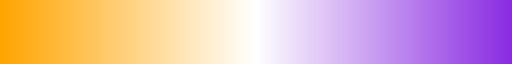

In [2]:
sydnor_sa_cmap = create_sydnor_sa_colormap()
sydnor_sa_cmap

In [3]:
dataset = 'HCP-YA'
which_modality = 'FMRI'
use_7t = False
# output_type = 'timescale_zero_crossing'
output_type = 'timescale_auc_zero_crossing'

# output_type = output_type + '_lp-0.01hz'
# output_type = output_type + '_hp-0.01hz'
# output_type = output_type + '_bp-0.01-0.08hz'
# output_type = output_type + '_bp-0.08-0.15hz'

use_resids = True
notebook_data = load_notebook_data(dataset=dataset, which_modality=which_modality,
                                   use_7t=use_7t, output_type=output_type, use_resids=use_resids,
                                   load_subject_data=False)

Loading data for notebooks...
Initialized DataLoader for dataset: HCP-YA
  Base directory:        /mnt/lindenmp_bignas/lindenmp/research_data/HCP_YA
  Raw data directory:    /mnt/lindenmp_bignas/lindenmp/research_data/HCP_YA/HCP_1200
  Derivatives directory: /mnt/lindenmp_bignas/lindenmp/research_data/HCP_YA/derivatives
  Output directory:      /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
  Behavioral data:       1206 subjects

	Initialized Timescales for dataset: HCP-YA
	Output directory: /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
Loaded 15456 scans from scan_registry_HCP-YA.csv


Loading metric_tsnr: 100%|██████████| 15456/15456 [00:02<00:00, 7604.48it/s]


15456
timescale_auc_zero_crossing


Loading timescale_auc_zero_crossing: 100%|██████████| 15456/15456 [00:01<00:00, 7996.14it/s]


15456


Loading timescale_auc_zero_crossing_resids: 100%|██████████| 15456/15456 [00:01<00:00, 7988.28it/s]

15456
Number of subjects: 966


In [4]:
%matplotlib inline
plt.rcParams.update({
    'font.size':            8,
    'figure.dpi':           300,
    'svg.fonttype':         "none",
    'font.family':          'sans-serif',
    'font.sans-serif':      ['Roboto'],
    'axes.spines.top':      True,
    'axes.spines.right':    True
})

nas_scratch_dir = f'/mnt/lindenmp_nas/lindenmp/work/figure_scratch/intrinsic_neural_timescales'
if not os.path.exists(nas_scratch_dir):
    os.mkdir(nas_scratch_dir)

In [5]:
# get key outputs for this notebook
timescales_processor = notebook_data['timescales_processor']
data_dict = notebook_data['data_dict']
data_dict_tsnr = notebook_data['data_dict_tsnr']
results_dir = notebook_data['results_dir']

df_neuro = notebook_data['supporting_data']['df_neuro']
distance_matrix = notebook_data['supporting_data']['distance_matrix']
gene_expression_nanmask = notebook_data['supporting_data']['gene_expression_nanmask']
yeo_systems = notebook_data['supporting_data']['yeo_systems']

print(data_dict.keys())
print(df_neuro.columns)

dict_keys(['sub-100206_task-rfMRIREST1LR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-rest', 'sub-100206_task-rfMRIREST1RL_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-rest', 'sub-100206_task-rfMRIREST2LR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-rest', 'sub-100206_task-rfMRIREST2RL_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-rest', 'sub-100206_task-tfMRIWMLR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100206_task-tfMRIWMRL_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100206_task-tfMRIEMOTIONLR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100206_task-tfMRIEMOTIONRL_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100206_task-tfMRIGAMBLINGLR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100206_task-tfMRIGAMBLINGRL_space-fsLR

In [6]:
n_regions = len(yeo_systems)
n_systems = len(np.unique(yeo_systems))

In [7]:
subject_ids = list(dict.fromkeys(scan.subject_id for scan in timescales_processor.scan_registry))
n_subs = len(subject_ids)
print(f'Number of subjects: {n_subs}')

Number of subjects: 966


In [8]:
timescales_processor.scan_registry[:5]

[ScanInfo(subject_id='100206', task='rfMRIREST1LR', space='fsLR', seg='Schaefer4007', modality='MRI3T', tr=0.72, session='01', stat='mean', run=None, desc=None, den=None, rbc=False),
 ScanInfo(subject_id='100206', task='rfMRIREST1RL', space='fsLR', seg='Schaefer4007', modality='MRI3T', tr=0.72, session='01', stat='mean', run=None, desc=None, den=None, rbc=False),
 ScanInfo(subject_id='100206', task='rfMRIREST2LR', space='fsLR', seg='Schaefer4007', modality='MRI3T', tr=0.72, session='01', stat='mean', run=None, desc=None, den=None, rbc=False),
 ScanInfo(subject_id='100206', task='rfMRIREST2RL', space='fsLR', seg='Schaefer4007', modality='MRI3T', tr=0.72, session='01', stat='mean', run=None, desc=None, den=None, rbc=False),
 ScanInfo(subject_id='100206', task='tfMRIWMLR', space='fsLR', seg='Schaefer4007', modality='MRI3T', tr=0.72, session='01', stat='mean', run=None, desc=None, den=None, rbc=False)]

In [9]:
if dataset == 'HCP-YA':
    scans_to_keep = ['rfMRIREST1LR', 'rfMRIREST1RL', 'rfMRIREST2LR', 'rfMRIREST2RL']
    # scans_to_keep = ['rfMRIREST1LR', 'rfMRIREST1RL']
    # scans_to_keep = ['rfMRIREST1LR', 'rfMRIREST2LR']
    condition_name = 'WM' # 'ALL', 'WM', 'EMOTION', 'GAMBLING', 'LANGUAGE', 'RELATIONAL', 'SOCIAL'

    if 'ALL' in condition_name:
        tasks = [
                'tfMRIWMLR', 'tfMRIWMRL',
                'tfMRIEMOTIONLR', 'tfMRIEMOTIONRL',
                'tfMRIGAMBLINGLR', 'tfMRIGAMBLINGRL',
                'tfMRILANGUAGELR', 'tfMRILANGUAGERL',
                'tfMRIRELATIONALLR', 'tfMRIRELATIONALRL',
                'tfMRISOCIALLR', 'tfMRISOCIALRL',
                ]
        scans_to_keep = scans_to_keep + tasks
        task_performance = []
    elif 'WM' in condition_name:
        scans_to_keep.append('tfMRIWMLR')
        scans_to_keep.append('tfMRIWMRL')
        task_performance = ['WM_Task_Acc', 'WM_Task_Median_RT']
    elif 'EMOTION' in condition_name:
        scans_to_keep.append('tfMRIEMOTIONLR')
        scans_to_keep.append('tfMRIEMOTIONRL')
        task_performance = ['EMOTION_Task_Acc', 'EMOTION_Task_Median_RT']
    elif 'GAMBLING' in condition_name:
        scans_to_keep.append('tfMRIGAMBLINGLR')
        scans_to_keep.append('tfMRIGAMBLINGRL')
        task_performance = ['GAMBLING_Task_Perc_Larger', 'GAMBLING_Task_Perc_Smaller']
    elif 'LANGUAGE' in condition_name:
        scans_to_keep.append('tfMRILANGUAGELR')
        scans_to_keep.append('tfMRILANGUAGERL')
        task_performance = ['LANGUAGE_Task_Acc', 'LANGUAGE_Task_Median_RT']
    elif 'RELATIONAL' in condition_name:
        scans_to_keep.append('tfMRIRELATIONALLR')
        scans_to_keep.append('tfMRIRELATIONALRL')
        task_performance = ['RELATIONAL_Task_Acc', 'RELATIONAL_Task_Median_RT']
    elif 'SOCIAL' in condition_name:
        scans_to_keep.append('tfMRISOCIALLR')
        scans_to_keep.append('tfMRISOCIALRL')
        task_performance = ['SOCIAL_Task_Perc_Random', 'SOCIAL_Task_Perc_TOM'] 

    # scan_registry_filtered = pd.DataFrame(columns=timescales_processor.scan_registry.columns)
    # for scan in scans_to_keep:
    #     # print(scan)
    #     subject_filter = timescales_processor.scan_registry['task'] == scan
    #     scan_registry_filtered = pd.concat((scan_registry_filtered, timescales_processor.scan_registry.loc[subject_filter])).reset_index(drop=True)
        
    # timescales_processor.scan_registry = scan_registry_filtered

In [10]:
cognitive_measures = [
    'CogTotalComp_Unadj',    # Total cognition composite
    'CogEarlyComp_Unadj',    # Early cognition composite
    'CogFluidComp_Unadj',    # Fluid intelligence
    'CogCrystalComp_Unadj',  # Crystallized intelligence
]

In [11]:
timescales_processor.match_registry_to_behavior()
print(timescales_processor.df_behavior_matched.shape)

(966, 584)


In [12]:
df_behavior = timescales_processor.df_behavior_matched.copy()
df_behavior.head()

,Release,Acquisition,Gender,Age,3T_Full_MR_Compl,T1_Count,T2_Count,3T_RS-fMRI_Count,3T_RS-fMRI_PctCompl,3T_Full_Task_fMRI,...,SSAGA_Times_Used_Hallucinogens,SSAGA_Times_Used_Opiates,SSAGA_Times_Used_Sedatives,SSAGA_Times_Used_Stimulants,SSAGA_Mj_Use,SSAGA_Mj_Ab_Dep,SSAGA_Mj_Age_1st_Use,SSAGA_Mj_Times_Used,age,sex
subject_id,,,,,,,,,,,,,,,,,,,,,
100206,S900,Q11,M,26-30,True,1,1,4,100.0,True,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,27,1
100307,Q1,Q01,F,26-30,True,1,1,4,100.0,True,...,0.0,0.0,0.0,0.0,1.0,0.0,2.0,1.0,27,0
100408,Q3,Q03,M,31-35,True,1,1,4,100.0,True,...,5.0,5.0,0.0,0.0,1.0,1.0,2.0,4.0,33,1
100610,S900,Q08,M,26-30,True,2,1,4,100.0,True,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,27,1
101006,S500,Q06,F,31-35,True,2,2,4,100.0,True,...,0.0,0.0,0.0,0.0,1.0,0.0,2.0,5.0,35,0


# Data for figures

In [13]:
brain_map = 'SA_Axis'

data_dict_converted = convert_data_dict(data_dict, timescales_processor.scan_registry)
data_dict_converted = average_data_dict_converted(data_dict_converted, average_3t_rest=True, average_3t_task_pairs=True)
data_dict_converted.keys()

rfMRIREST1LR (966, 400)
rfMRIREST1RL (966, 400)
rfMRIREST2LR (966, 400)
rfMRIREST2RL (966, 400)
tfMRIWMLR (966, 400)
tfMRIWMRL (966, 400)
tfMRIEMOTIONLR (966, 400)
tfMRIEMOTIONRL (966, 400)
tfMRIGAMBLINGLR (966, 400)
tfMRIGAMBLINGRL (966, 400)
tfMRILANGUAGELR (966, 400)
tfMRILANGUAGERL (966, 400)
tfMRIRELATIONALLR (966, 400)
tfMRIRELATIONALRL (966, 400)
tfMRISOCIALLR (966, 400)
tfMRISOCIALRL (966, 400)


dict_keys(['task-REST_3T', 'task-WM', 'task-EMOTION', 'task-GAMBLING', 'task-LANGUAGE', 'task-RELATIONAL', 'task-SOCIAL'])

## Subject-level analyses: regional

In [14]:
def compute_regional_corrs(rest_data, task_data, behavior_data):
    # Compute correlations for each region
    n_regions = rest_data.shape[1]
    rest_correlations = np.zeros(n_regions)
    task_correlations = np.zeros(n_regions)
    deflection_correlations = np.zeros(n_regions)
    rest_pvalues = np.zeros(n_regions)
    task_pvalues = np.zeros(n_regions)
    deflection_pvalues = np.zeros(n_regions)

    # Remove subjects with missing behavioral data
    valid_subjects = ~np.isnan(behavior_data)
    behavior_clean = behavior_data[valid_subjects]
    rest_clean = rest_data[valid_subjects, :]
    task_clean = task_data[valid_subjects, :]

    print(f"  Valid subjects: {np.sum(valid_subjects)}/{len(behavior_data)}")

    for region_idx in range(n_regions):
        # Rest condition correlations
        rest_region_data = rest_clean[:, region_idx]
        rest_correlations[region_idx], rest_pvalues[region_idx] = sp.stats.spearmanr(rest_region_data, behavior_clean)
        
        # Task condition correlations
        task_region_data = task_clean[:, region_idx]
        task_correlations[region_idx], task_pvalues[region_idx] = sp.stats.spearmanr(task_region_data, behavior_clean)
        
        # Task condition correlations
        deflection_region_data = compute_deflections(rest_clean[:, region_idx], task_clean[:, region_idx],
                                                     nuisance_regression=False, absolute=True)
        deflection_correlations[region_idx], deflection_pvalues[region_idx] = sp.stats.spearmanr(deflection_region_data, behavior_clean)
        
    return rest_correlations, task_correlations, deflection_correlations

## INT deflection variance and covariance

In [15]:
# Neural data for rest and task
rest_data = data_dict_converted['task-REST_3T']           # (n_subjects, n_regions)
task_data = data_dict_converted[f'task-{condition_name}'] # (n_subjects, n_regions)

behavior_measures = [
    f'{condition_name}_Task_Acc',
    f'{condition_name}_Task_Median_RT',
    'CogTotalComp_Unadj',
]

# Compute subject-level absolute deflection matrix (n_subjects × n_regions)
deflection_matrix = np.column_stack([
    compute_deflections(rest_data[:, r], task_data[:, r], nuisance_regression=False, absolute=True)
    for r in range(n_regions)
])

# Build tSNR mask: exclude lowest 10% tSNR regions for the task condition
df_tsnr = create_ints_dataframe_custom_grouping(data_dict_tsnr, average_3t_task_pairs=True)
tsnr_col = f'task-{condition_name}'
region_mask = (df_tsnr[tsnr_col] < np.quantile(df_tsnr[tsnr_col], q=0.1)).values

# Apply mask — drops low-tSNR regions from data arrays and SA axis
sa_axis_masked = df_neuro[brain_map].values.copy()
rest_data, task_data, deflection_matrix, sa_axis_masked = apply_region_mask(
    region_mask, rest_data, task_data, deflection_matrix, sa_axis=sa_axis_masked)
yeo_systems_masked = np.asarray(yeo_systems)[~region_mask]

# Per-region statistics on masked data
mean_deflection = np.nanmean(deflection_matrix, axis=0)  # (n_regions_valid,)
std_deflection  = np.nanstd(deflection_matrix, axis=0)   # (n_regions_valid,)
cv_deflection   = std_deflection / mean_deflection        # coefficient of variation

print(f'deflection_matrix: {deflection_matrix.shape}')
print(f'mean_deflection:   {mean_deflection.shape}')

region_mask: excluding 40 regions, 360 remaining.
deflection_matrix: (966, 360)
mean_deflection:   (360,)


  Valid subjects: 966/966
  Valid subjects: 960/966
  Valid subjects: 953/966


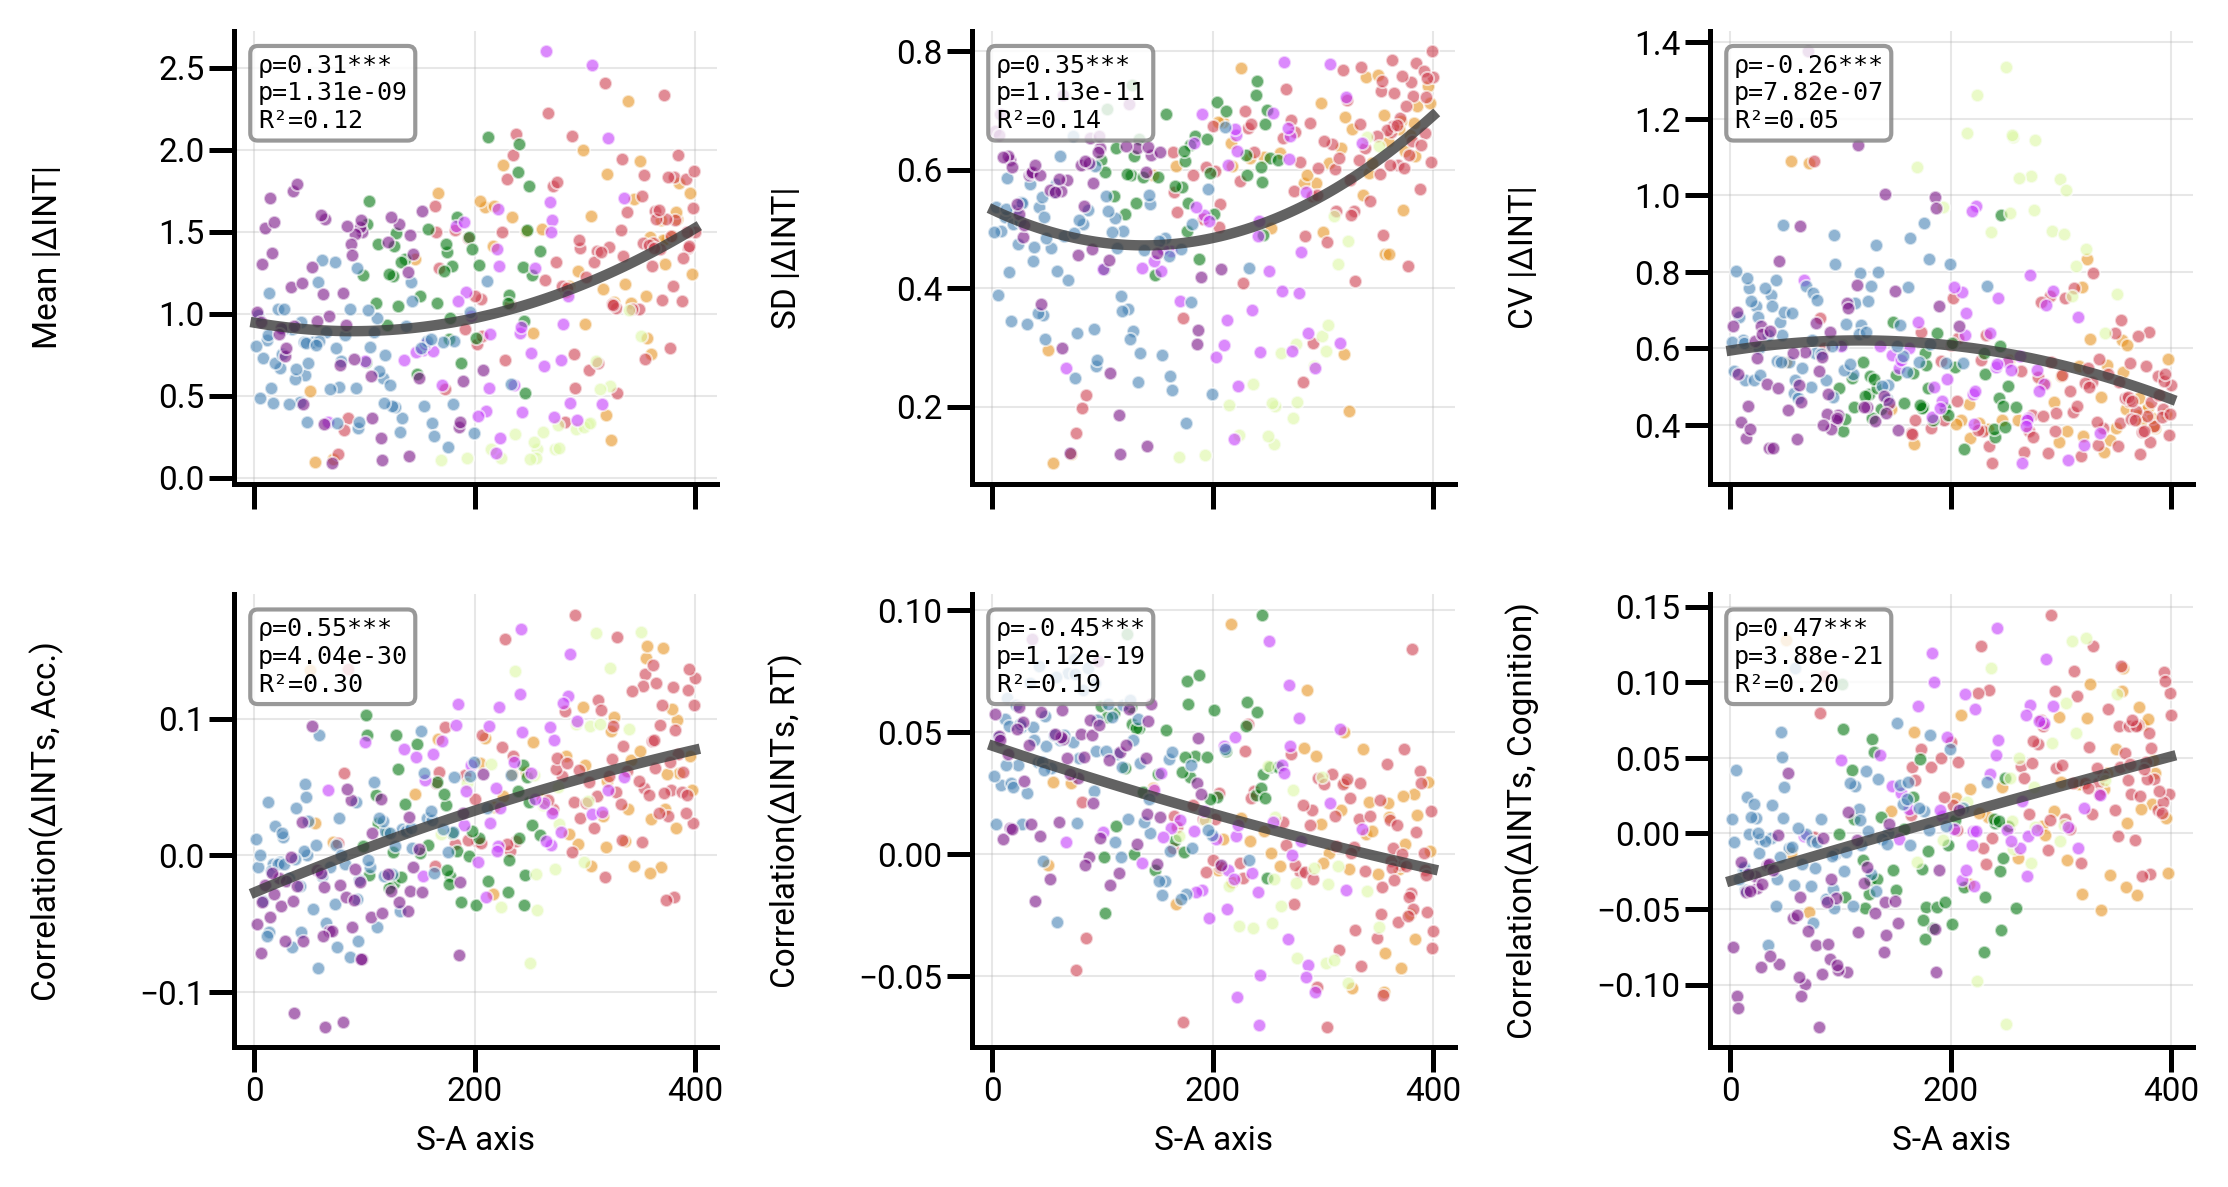

In [27]:
fig, axes = plt.subplots(nrows=2, ncols=len(behavior_measures),
                         sharex=True, sharey=False,
                         figsize=(len(behavior_measures)*2.5, 4), dpi=300)

# Top row: variance characterization (no behavior)
variance_panels = [
    (mean_deflection, 'Mean |ΔINT|'),
    (std_deflection,  'SD |ΔINT|'),
    (cv_deflection,   'CV |ΔINT|'),
]
for i, (stat_data, stat_label) in enumerate(variance_panels):
    plot_correlation(sa_axis_masked, stat_data, axes[0, i],
                     data_group=yeo_systems_masked, show_stats=True, fontsize=8, method='spearman',
                     y_label=stat_label, x_label=' ', size=10, cbar_label='Yeo Systems',
                     show_colorbar=False, data_group_cmap='yeo7',
                     auto_polynomial=True, models_to_test=[1, 2],
                     model_selection_metric='variance_explained')

# Bottom row: behavioral covariance
for i, behavior_measure in enumerate(behavior_measures):
    behavior_data = df_behavior[behavior_measure].values.astype(float)
    rest_correlations, task_correlations, deflection_correlations = compute_regional_corrs(
        rest_data, task_data, behavior_data)

    if 'Acc' in behavior_measure:
        y_sublabel = 'Acc.'
    elif 'RT' in behavior_measure:
        y_sublabel = 'RT'
    else:
        y_sublabel = 'Cognition'

    file_label = f'Correlation(ΔINTs, {y_sublabel})'
    plot_correlation(sa_axis_masked, deflection_correlations, axes[1, i],
                     data_group=yeo_systems_masked, show_stats=True, fontsize=8, method='spearman',
                     y_label=file_label, x_label='S-A axis', size=10, cbar_label='Yeo Systems',
                     show_colorbar=False, data_group_cmap='yeo7',
                     auto_polynomial=True, models_to_test=[1, 2],
                     model_selection_metric='variance_explained')

for ax in axes.flat:
    # ax.set_xlabel('S-A axis')
    ax.tick_params(axis='y', which='major', pad=1)
    ax.tick_params(axis='x', which='major', pad=1)
    ax.yaxis.set_label_coords(-0.35, 0.5)

fig.tight_layout()
fig.savefig(os.path.join(nas_scratch_dir, f'corr_ints_sa.png'), bbox_inches='tight', dpi=1000, transparent=True)
plt.show()

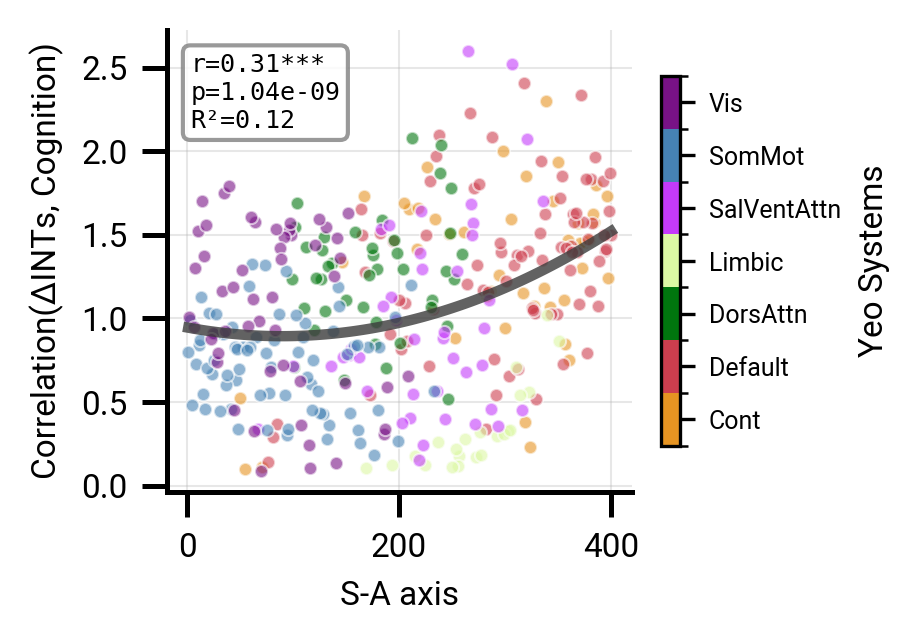

In [24]:
# another one just for the colorbar
fig, axes = plt.subplots(nrows=1, ncols=1,
                         sharex=True, sharey=False,
                         figsize=(2.5, 2), dpi=300)

plot_correlation(sa_axis_masked, mean_deflection, axes, 
                data_group=yeo_systems_masked, show_stats=True, fontsize=8,
                y_label=file_label, x_label='S-A axis', size=10, cbar_label='Yeo Systems', show_colorbar=True, data_group_cmap='yeo7',
                auto_polynomial=True, models_to_test=[1, 2], model_selection_metric='variance_explained')

fig.savefig(os.path.join(nas_scratch_dir, f'corr_ints_sa_colorbar.png'), bbox_inches='tight', dpi=1000, transparent=True)
plt.show()